## Explaining Phishing Detectors

The same fixed split and random_state=42 are used throughout so the different learning methods can be compared fairly.

In [25]:
import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.tree import DecisionTreeClassifier, export_text

import shap
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## Part A - Train the phishing detectors

### A1. Load the dataset

In [26]:
# Use the dataset file from data/ folder.

data_file = Path("data") / "dataset_phishing.csv"

df = pd.read_csv(data_file)

print("Dataset shape:", df.shape)
print("\nStatus counts:")
print(df["status"].value_counts())
display(df.head())

Dataset shape: (11430, 89)

Status counts:
status
legitimate    5715
phishing      5715
Name: count, dtype: int64


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


### A2. Prepare the data and create the 60/20/20 split

In [27]:
# 1 = phishing and 0 = legitimate.
y = (df["status"] == "phishing").astype(int)

# The raw URL string is not used as a numeric feature.
X = df.drop(columns=["url", "status"]).astype(float)

# 60% train, 20% validation and 20% test.
# Stratification keeps the phishing/legitimate balance the same in each split.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print("Train/validation/test sizes:",
      len(X_train), len(X_val), len(X_test))
print("Training phishing share:", round(y_train.mean(), 3))

Train/validation/test sizes: 6858 2286 2286
Training phishing share: 0.5


### A3. Evaluation helper

The lab compares models using Macro-F1, recall, ROC-AUC and FAR.

In [28]:
def report(model, X_data, y_data):
    pred = model.predict(X_data)
    prob = model.predict_proba(X_data)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_data, pred, labels=[0, 1]
    ).ravel()

    scores = {
        "macro_F1": f1_score(y_data, pred, average="macro"),
        "recall": recall_score(y_data, pred),
        "ROC_AUC": roc_auc_score(y_data, prob),
        "FAR": fp / (fp + tn),
    }

    return {name: round(float(value), 3)
            for name, value in scores.items()}

### A4-A6. Supervised models

A small decision tree and logistic regression are the glass-box models.  
The 300-tree Random Forest is the supervised black-box model.

In [29]:
# ----- Small Decision Tree -----
# Choose between depth 3 and 4 using validation Macro-F1 only.
best_score = -1
tree = None

for depth in [3, 4]:
    candidate = DecisionTreeClassifier(
        max_depth=depth,
        random_state=SEED,
    )
    candidate.fit(X_train, y_train)

    score = report(candidate, X_val, y_val)["macro_F1"]
    print("depth", depth, "validation Macro-F1:", score)

    if score > best_score:
        best_score = score
        tree = candidate

print("Kept tree depth:", tree.get_depth())


# ----- Logistic Regression -----
# Scaling is inside the pipeline, so it is fitted on training data only.
logreg = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, random_state=SEED)),
])

logreg.fit(X_train, y_train)
print("\nLogistic Regression:", report(logreg, X_val, y_val))


# ----- Random Forest -----
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
)

rf.fit(X_train, y_train)
print("Random Forest:", report(rf, X_val, y_val))

depth 3 validation Macro-F1: 0.913
depth 4 validation Macro-F1: 0.925
Kept tree depth: 4

Logistic Regression: {'macro_F1': 0.938, 'recall': 0.933, 'ROC_AUC': 0.983, 'FAR': 0.056}
Random Forest: {'macro_F1': 0.96, 'recall': 0.966, 'ROC_AUC': 0.993, 'FAR': 0.046}


### A7. Keep only 5% of the training labels

These are the two lower-line models. The hidden labels are never used for training.

In [30]:
X_lab, X_unlab, y_lab, y_hidden = train_test_split(
    X_train,
    y_train,
    train_size=0.05,
    stratify=y_train,
    random_state=SEED,
)

print(len(X_lab), "labelled,", len(X_unlab), "unlabelled")


# Lower line for the Random Forest.
rf_few = RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1,)
rf_few.fit(X_lab, y_lab)

print("Forest, 5% labels:",report(rf_few, X_val, y_val))


# Lower line for Logistic Regression.
logreg_few = Pipeline([
    ("scale", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, random_state=SEED)),
])
logreg_few.fit(X_lab, y_lab)

print("LogReg, 5% labels:",report(logreg_few, X_val, y_val))

342 labelled, 6516 unlabelled
Forest, 5% labels: {'macro_F1': 0.938, 'recall': 0.946, 'ROC_AUC': 0.984, 'FAR': 0.069}
LogReg, 5% labels: {'macro_F1': 0.912, 'recall': 0.915, 'ROC_AUC': 0.962, 'FAR': 0.092}


### A8. Semi-supervised learning with pseudo-labelling

The forest starts with the real 5% labels. In each round it adds only predictions with at least 0.90 confidence.

In [ ]:
X_now = X_lab.copy()
y_now = y_lab.copy()
pool = X_unlab.copy()

rf_semi = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
)

CUTOFF = 0.90

for rnd in [1, 2, 3]:
    rf_semi.fit(X_now, y_now)

    p = rf_semi.predict_proba(pool)[:, 1]

    # Keep very confident phishing or legitimate predictions.
    sure = (p >= CUTOFF) | ((1 - p) >= CUTOFF)

    guessed_labels = pd.Series(
        (p[sure] >= 0.5).astype(int),
        index=pool.index[sure],
    )

    # y_hidden is used only to inspect pseudo-label quality.
    # It is NOT added to the training data.
    if sure.sum() > 0:
        hidden_true = y_hidden.loc[guessed_labels.index]
        guess_accuracy = (guessed_labels == hidden_true).mean()
    else:
        guess_accuracy = np.nan

    X_now = pd.concat([X_now, pool.loc[sure]])
    y_now = pd.concat([y_now, guessed_labels])
    pool = pool.loc[~sure]

    print(
        f"round {rnd}: added {sure.sum()} guesses, "
        f"{len(pool)} still unlabelled, "
        f"guess accuracy = {guess_accuracy:.3f}"
    )

    if len(pool) == 0:
        break

# Final fit on real labels + accepted pseudo-labels.
rf_semi.fit(X_now, y_now)

print("\nSemi-supervised:",report(rf_semi, X_val, y_val))

round 1: added 2782 guesses, 3734 still unlabelled, guess accuracy = 0.994
round 2: added 1130 guesses, 2604 still unlabelled, guess accuracy = 0.984
round 3: added 414 guesses, 2190 still unlabelled, guess accuracy = 0.952

Semi-supervised: {'macro_F1': 0.932, 'recall': 0.946, 'ROC_AUC': 0.981, 'FAR': 0.082}


### A9. Self-supervised learning

A small reconstruction network first learns from all training URLs without labels.  
Its 32-dimensional hidden representation is then used with the same 5% labelled subset.

In [32]:
# Scaling does not use labels, so it can be fitted on the full training split.
scaler = StandardScaler().fit(X_train)
Z = scaler.transform(X_train)

# Hide 20% of the scaled feature values.
rng = np.random.default_rng(SEED)
hidden_part = rng.random(Z.shape) < 0.20
Z_masked = np.where(hidden_part, 0.0, Z)

# Learn to reconstruct the complete row from the masked row.
ae = MLPRegressor(
    hidden_layer_sizes=(32,),
    max_iter=300,
    random_state=SEED,
)
ae.fit(Z_masked, Z)

print("Fill-in error:", round(ae.loss_, 3))


def encode(X_data):
    # Recreate the 32 hidden activations learned by the MLP.
    scaled = scaler.transform(X_data)
    hidden = scaled @ ae.coefs_[0] + ae.intercepts_[0]
    return np.maximum(hidden, 0.0)


self_sup = Pipeline([
    ("encode", FunctionTransformer(encode, validate=False)),
    ("lr", LogisticRegression(max_iter=1000, random_state=SEED)),
])

self_sup.fit(X_lab, y_lab)

print("Self-supervised:",report(self_sup, X_val, y_val))

Fill-in error: 0.167
Self-supervised: {'macro_F1': 0.914, 'recall': 0.918, 'ROC_AUC': 0.966, 'FAR': 0.09}


### A10. Final comparison on the untouched test set

In [33]:
models = {
    "tree": tree,
    "logreg": logreg,
    "forest (100%)": rf,
    "forest (5%)": rf_few,
    "logreg (5%)": logreg_few,
    "semi-supervised": rf_semi,
    "self-supervised": self_sup,
}

results = pd.DataFrame({
    name: report(model, X_test, y_test)
    for name, model in models.items()
}).T

display(results.round(3))

print(
    "Semi-supervised minus forest (5%) Macro-F1:",
    round(results.loc["semi-supervised", "macro_F1"]- results.loc["forest (5%)", "macro_F1"],3,),)

print(
    "Self-supervised minus logreg (5%) Macro-F1:",
    round(results.loc["self-supervised", "macro_F1"]- results.loc["logreg (5%)", "macro_F1"], 3,),)

,macro_F1,recall,ROC_AUC,FAR
tree,0.927,0.912,0.953,0.057
logreg,0.947,0.943,0.985,0.050
forest (100%),0.965,0.967,0.994,0.037
forest (5%),0.940,0.942,0.985,0.062
logreg (5%),0.912,0.908,0.963,0.084
semi-supervised,0.934,0.940,0.980,0.071
self-supervised,0.918,0.922,0.970,0.087


Semi-supervised minus forest (5%) Macro-F1: -0.006
Self-supervised minus logreg (5%) Macro-F1: 0.006


### Check yourself :
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Did semi-supervised beat forest (5%)? Did self-supervised beat logreg (5%)? These two comparisons tell you whether the unlabelled data helped.</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The semi-supervised Random Forest did not outperform the Random Forest trained on only 5% labelled data. Its Macro-F1 decreased from 0.940 to 0.934, while FAR increased from 0.062 to 0.071. So the pseudo-labelled samples did not help in this setup. Random Forest already learned a good boundary from the small labelled subset, and the remaining pseudo-label errors may have introduced some additional noise.
<br>The self-supervised model did beat the low-label logistic regression, but only by a small margin: its Macro-F1 went from 0.912 to 0.918. This means the unlabelled data helped a little, but not enough to match the full supervised models.</p>

## Part B - Explain the detectors

### B1. Read the glass-box models

In [34]:
# Decision tree rules.
tree_rules = export_text(tree,feature_names=list(X_train.columns),)

print(tree_rules)
print("Tree leaves:", tree.get_n_leaves())

# Logistic Regression weights.
# The inputs were standardized, so the coefficients can be compared more directly.
weights = pd.Series(logreg.named_steps["lr"].coef_[0], index=X_train.columns,)

top10_logreg = weights.abs().sort_values(ascending=False).index[:10]

print("\n10 strongest Logistic Regression weights:")
print(weights[top10_logreg].round(3))
print("\nLogReg weights with |w| > 0.01:",int((weights.abs() > 0.01).sum()),)

|--- google_index <= 0.50
|   |--- page_rank <= 0.50
|   |   |--- shortest_word_path <= 0.50
|   |   |   |--- nb_www <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- nb_www >  0.50
|   |   |   |   |--- class: 0
|   |   |--- shortest_word_path >  0.50
|   |   |   |--- nb_hyphens <= 4.50
|   |   |   |   |--- class: 1
|   |   |   |--- nb_hyphens >  4.50
|   |   |   |   |--- class: 0
|   |--- page_rank >  0.50
|   |   |--- nb_qm <= 0.50
|   |   |   |--- phish_hints <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- phish_hints >  1.50
|   |   |   |   |--- class: 1
|   |   |--- nb_qm >  0.50
|   |   |   |--- nb_hyperlinks <= 32.50
|   |   |   |   |--- class: 1
|   |   |   |--- nb_hyperlinks >  32.50
|   |   |   |   |--- class: 0
|--- google_index >  0.50
|   |--- page_rank <= 2.50
|   |   |--- domain_in_brand <= 0.50
|   |   |   |--- ratio_extRedirection <= 1.58
|   |   |   |   |--- class: 1
|   |   |   |--- ratio_extRedirection >  1.58
|   |   |   |   |--- class: 0
|   |   |--- d

### Check yourself 
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Write the tree's first question in plain English. Does it make sense to a security person?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">We got the value as google_index <= 0.50 i.e google_index = 0 
so the question becomes "Is this page indexed by Google?” 
This makes sense from a security perspective because phishing websites are often newly created, short-lived domains and may not yet have been indexed by search engines. An unindexed website is therefore a useful phishing indicator, although it should not be used alone because legitimate new websites may also be unindexed. </p>

### B2. SHAP for the supervised Random Forest

Raw SHAP shape: (500, 87, 2)


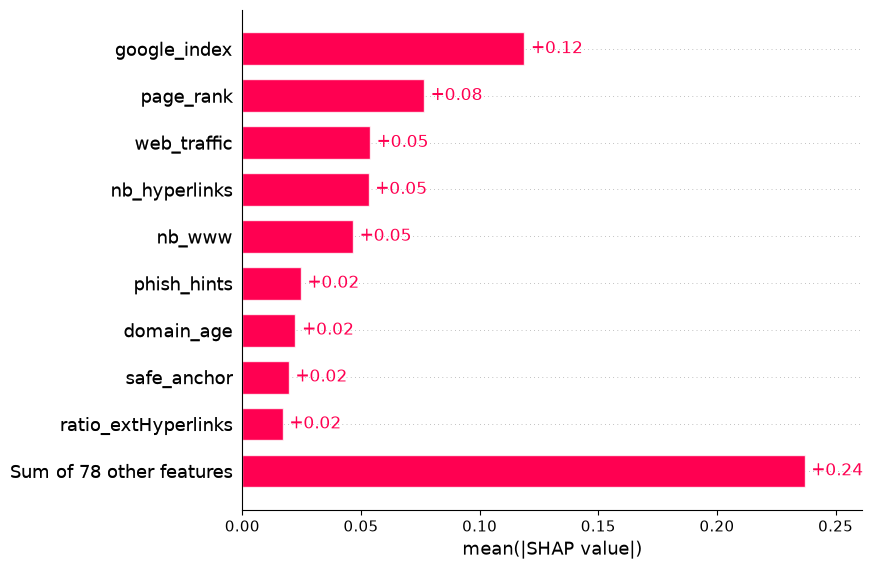

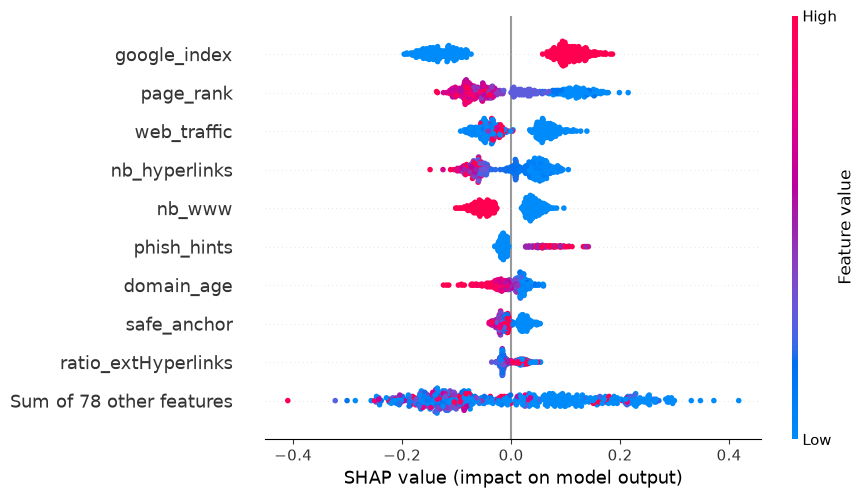


Supervised forest SHAP top 10:
google_index            0.1188
page_rank               0.0766
web_traffic             0.0538
nb_hyperlinks           0.0532
nb_www                  0.0467
phish_hints             0.0246
domain_age              0.0224
safe_anchor             0.0196
ratio_extHyperlinks     0.0170
ratio_extRedirection    0.0143
dtype: float64


In [35]:
def phishing_shap(explanation):
    # Newer SHAP versions return one set of values per class for tree classifiers.
    if explanation.values.ndim == 3:
        return explanation[:, :, 1]
    return explanation


explainer = shap.TreeExplainer(rf)

# 500 test URLs are used for the global explanation.
sv = explainer(X_test.iloc[:500])
print("Raw SHAP shape:", sv.values.shape)

sv1 = phishing_shap(sv)

shap.plots.bar(sv1, max_display=10)
shap.plots.beeswarm(sv1, max_display=10)

shap_top = pd.Series(
    np.abs(sv1.values).mean(axis=0),
    index=X_test.columns,).sort_values(ascending=False)

print("\nSupervised forest SHAP top 10:")
print(shap_top.head(10).round(4))

### Check yourself 
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">In the beeswarm, are the red dots of the top feature on the right or the left? What does that mean in plain words? </p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">for google_index the red dots are on the right side of the SHAP beeswarm. A high value of google_index therefore increases the phishing prediction. Since google_index = 1 means that Google has not indexed the website, the model has learned that unindexed websites are substantially more suspicious.</p>

### B3. SHAP for the semi-supervised and self-supervised models

Semi-supervised SHAP shape: (500, 87)
Self-supervised SHAP shape: (200, 87)


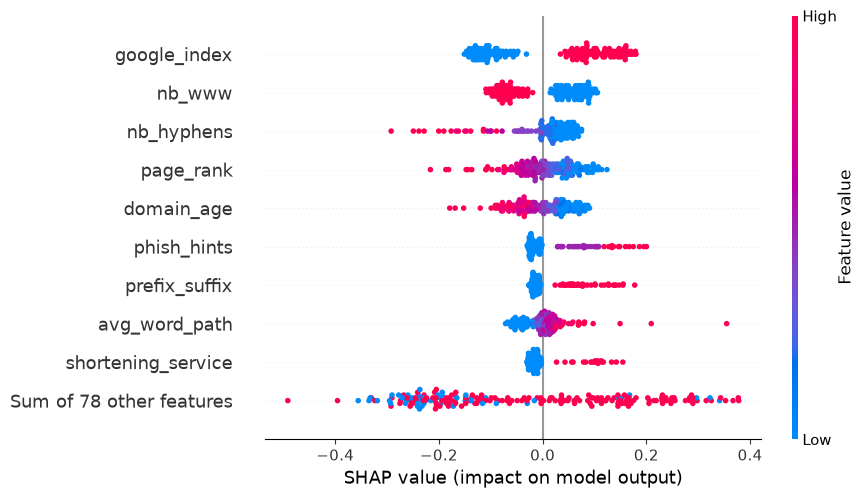

In [36]:
# Semi-supervised forest.
sv_semi_raw = shap.TreeExplainer(rf_semi)(
    X_test.iloc[:500]
)
sv_semi = phishing_shap(sv_semi_raw)


# The self-supervised pipeline is not a tree model,
# so SHAP explains its prediction function from the outside.
def self_prob(values):
    values = pd.DataFrame(
        values,
        columns=X_train.columns,)
    return self_sup.predict_proba(values)[:, 1]


background = X_train.sample(100,random_state=SEED,)
explainer_self = shap.Explainer(self_prob, background,)
sv_self = explainer_self(X_test.iloc[:200])

print("Semi-supervised SHAP shape:",sv_semi.values.shape,)
print("Self-supervised SHAP shape:",sv_self.values.shape,)

shap.plots.beeswarm(
    sv_self,
    max_display=10,
)

### B4. Compare the features used by the different models

In [37]:
def shap_top10(explanation):
    importance = pd.Series(
        np.abs(explanation.values).mean(axis=0),
        index=X_test.columns,
    )
    return importance.sort_values(
        ascending=False
    ).index[:10]


tree_importance = pd.Series(
    tree.feature_importances_,
    index=X_train.columns,
)

top_feature_lists = pd.DataFrame({
    "tree": tree_importance.sort_values(
        ascending=False
    ).index[:10],
    "logreg": weights.abs().sort_values(
        ascending=False
    ).index[:10],
    "SHAP forest": shap_top10(sv1),
    "SHAP semi": shap_top10(sv_semi),
    "SHAP self": shap_top10(sv_self),
})

display(top_feature_lists)

,tree,logreg,SHAP forest,SHAP semi,SHAP self
0,google_index,longest_words_raw,google_index,google_index,google_index
1,page_rank,page_rank,page_rank,web_traffic,nb_www
2,nb_hyperlinks,phish_hints,web_traffic,page_rank,nb_hyphens
3,nb_www,google_index,nb_hyperlinks,nb_hyperlinks,page_rank
4,nb_qm,avg_word_host,nb_www,nb_www,domain_age
5,web_traffic,nb_hyphens,phish_hints,ratio_extHyperlinks,phish_hints
6,phish_hints,nb_www,domain_age,char_repeat,prefix_suffix
7,shortest_word_path,length_hostname,safe_anchor,ratio_extRedirection,avg_word_path
8,domain_in_brand,nb_semicolumn,ratio_extHyperlinks,ratio_intHyperlinks,shortening_service
9,ratio_extRedirection,nb_hyperlinks,ratio_extRedirection,safe_anchor,domain_in_title


### Check yourself 
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Which features appear in almost every list? </p>
<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The features that appear most consistently across the models are google_index, page_rank, and nb_www. They appear in all 5 lists. phish_hints and nb_hyperlinks also appear in four of the five lists. This suggests that the different models agree on several important phishing indicators even though they use different learning methods.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Does the self-supervised model look at different clues from the two forests?</p>
<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The self-supervised model partly relies on different clues from the two Random Forest models. All three agree on important features such as google_index, page_rank, and nb_www. However, the forests rely more on features such as web_traffic, nb_hyperlinks, ratio_extHyperlinks, and ratio_extRedirection, while the self-supervised model gives more importance to URL-structure features such as nb_hyphens, prefix_suffix, avg_word_path, and shortening_service. Therefore, the self-supervised model has some overlap with the forests, but it has also learned a somewhat different feature representation.</p>

### B5. Pick three URLs for local explanations

In [38]:
prob = rf.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
yt = y_test.to_numpy()

# Most confident correct phishing prediction.
caught = np.where(
    (yt == 1) & (pred == 1)
)[0]
i_phish = caught[np.argmax(prob[caught])]

# Most confident correct legitimate prediction.
ok_legit = np.where(
    (yt == 0) & (pred == 0)
)[0]
i_legit = ok_legit[np.argmin(prob[ok_legit])]

# Most confident wrong prediction.
wrong = np.where(yt != pred)[0]

if len(wrong) > 0:
    i_wrong = wrong[
        np.argmax(
            np.abs(prob[wrong] - 0.5)
        )
    ]
else:
    # Fallback only if the forest happens to make no mistakes.
    i_wrong = np.argmin(
        np.abs(prob - 0.5)
    )

three = [
    ("phishing", i_phish),
    ("legitimate", i_legit),
    ("wrong", i_wrong),
]

for name, i in three:
    print(
        f"{name:10s} row {i}: "
        f"P(phishing) = {prob[i]:.3f}, " 
        f"true label = {yt[i]}")

phishing   row 34: P(phishing) = 1.000, true label = 1
legitimate row 10: P(phishing) = 0.000, true label = 0
wrong      row 1257: P(phishing) = 0.953, true label = 0


### B6. Local explanations with SHAP and LIME


SHAP - phishing


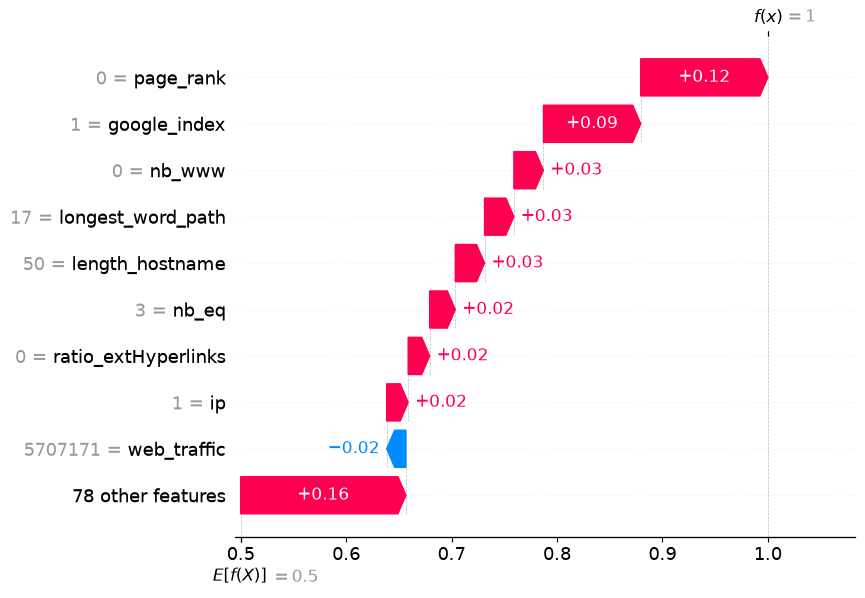


SHAP - legitimate


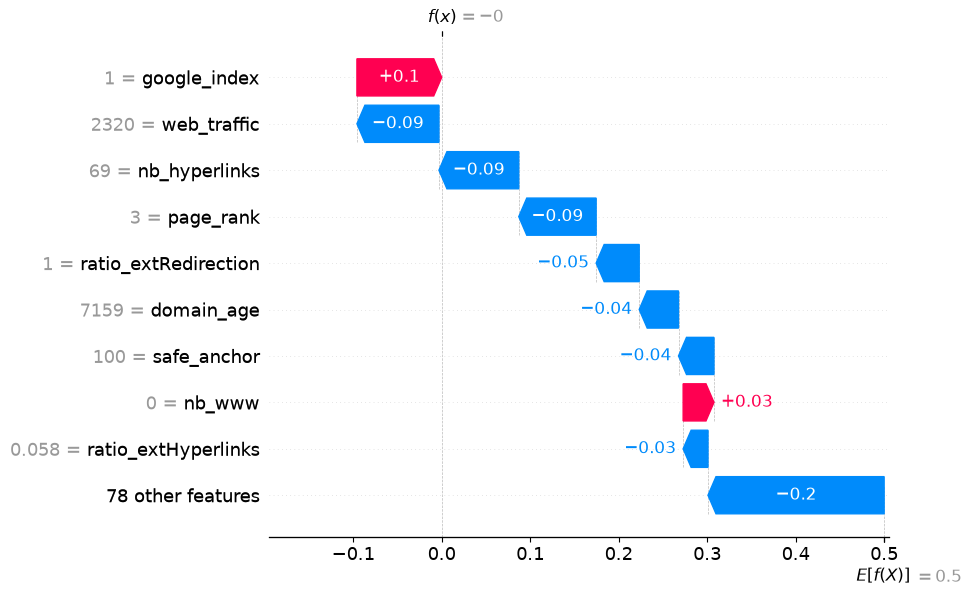


SHAP - wrong


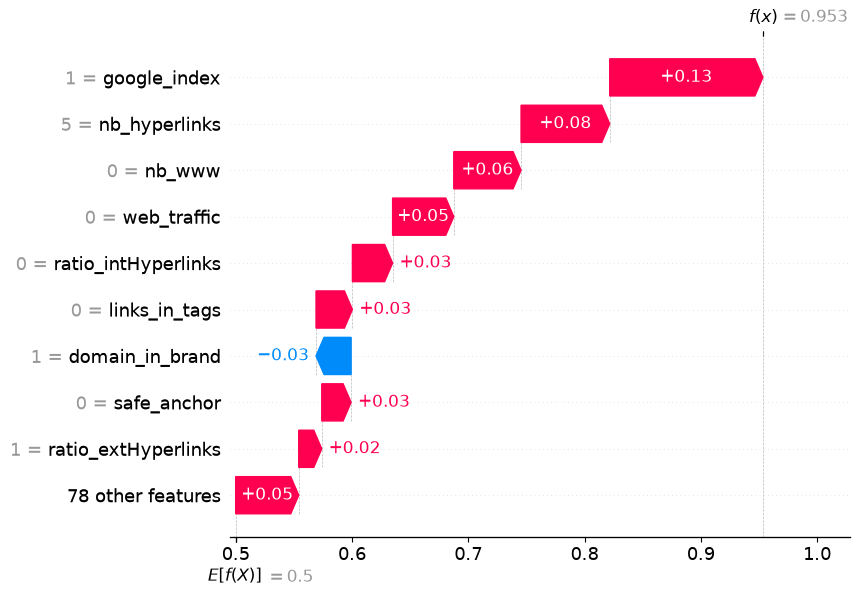

In [39]:
# SHAP waterfall plots for the same three URLs.
for name, i in three:
    one = phishing_shap(
        explainer(
            X_test.iloc[[i]]
        )
    )

    print("\nSHAP -", name)
    shap.plots.waterfall(one[0],max_display=10,)


 phishing - LIME fit score: 0.64
  0.00 < google_index <= 1.00         +0.190
  page_rank <= 1.00                   +0.161
  nb_www <= 0.00                      +0.085
  phish_hints <= 0.00                 -0.079
  longest_word_path > 11.00           +0.046
  longest_words_raw > 16.00           +0.046
  path_extension <= 0.00              +0.029
  right_clic <= 0.00                  -0.014


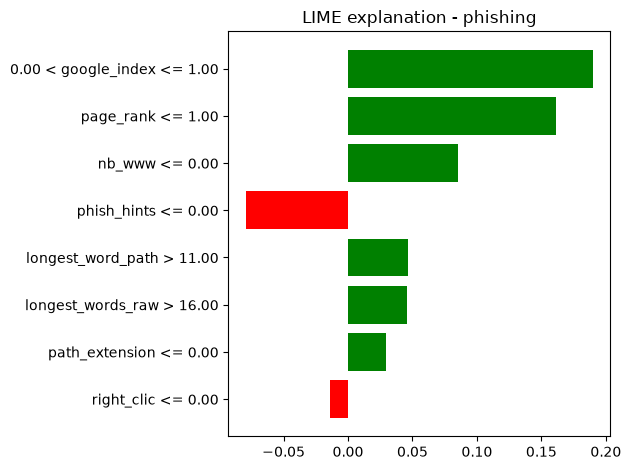


 legitimate - LIME fit score: 0.42
  0.00 < google_index <= 1.00         +0.192
  iframe <= 0.00                      -0.099
  nb_www <= 0.00                      +0.080
  phish_hints <= 0.00                 -0.074
  nb_star <= 0.00                     -0.057
  nb_external_redirection <= 0.00     +0.052
  domain_age > 7025.25                -0.045
  nb_comma <= 0.00                    -0.041


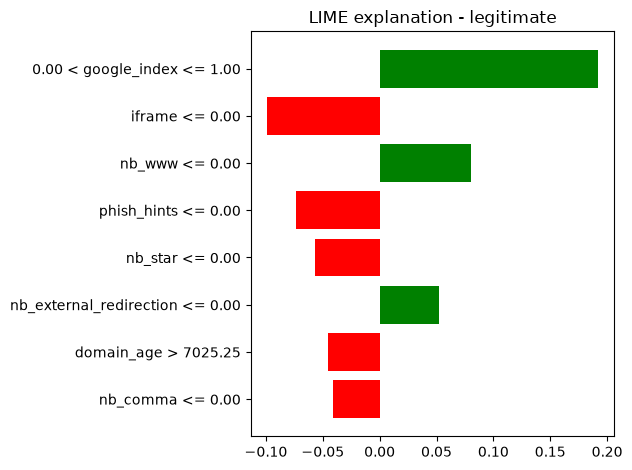


 wrong - LIME fit score: 0.48
  0.00 < google_index <= 1.00         +0.187
  nb_www <= 0.00                      +0.085
  web_traffic <= 0.00                 +0.076
  phish_hints <= 0.00                 -0.071
  nb_hyperlinks <= 8.00               +0.068
  punycode <= 0.00                    +0.067
  nb_star <= 0.00                     -0.053
  nb_dollar <= 0.00                   -0.048


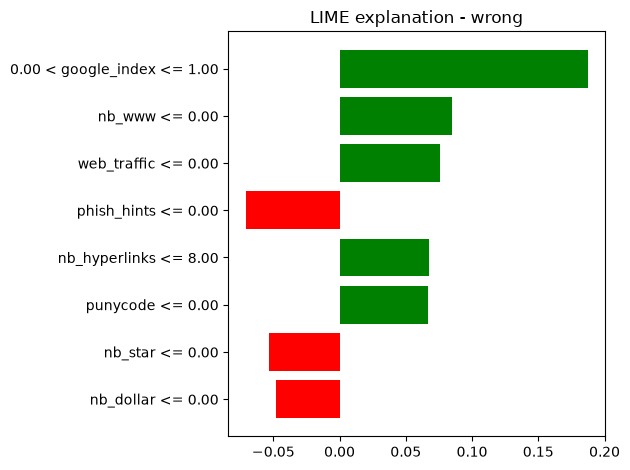

In [40]:
# LIME sends NumPy arrays to the model.
# Put the feature names back before calling the Random Forest.
def predict_fn(values, model=rf):
    frame = pd.DataFrame(values,columns=X_train.columns,)
    return model.predict_proba(frame)


lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X_train.columns),
    class_names=["legitimate", "phishing"],
    mode="classification",
    discretize_continuous=True,
    random_state=SEED,
)

lime_local_results = {}

for name, i in three:
    exp = lime_explainer.explain_instance(X_test.iloc[i].values,predict_fn,num_features=8,num_samples=5000,)

    lime_local_results[name] = exp

    print("\n", name, "- LIME fit score:",round(exp.score, 2),)

    for feature, weight in exp.as_list():
        print(f"  {feature:35s} "f"{weight:+.3f}")

    exp.as_pyplot_figure()
    plt.title(f"LIME explanation - {name}")
    plt.tight_layout()
    plt.show()

### Check yourself 
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">For the wrong URL: which features fooled the forest? Do SHAP and LIME name the same top 3 features?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">Both SHAP and LIME show that google_index and nb_www strongly pushed the prediction toward phishing. SHAP also identified nb_hyperlinks as one of the three strongest contributors, while LIME instead ranked web_traffic in its top three. Therefore, the two methods agree on two of the three most important local features. However, the LIME fit score was only 0.48, so this local explanation should be interpreted cautiously because LIME did not approximate the Random Forest particularly well around this sample.</p>

## Part C - Test the detector and the explanations

### C1. Remove the seven external lookup features

In [ ]:
# These seven features require information from outside the URL/page itself.
# This lets us test whether the detector still works when it only uses information
# that can be extracted directly from the URL or page structure.
EXTERNAL = [
    "whois_registered_domain",
    "domain_registration_length",
    "domain_age",
    "web_traffic",
    "dns_record",
    "google_index",
    "page_rank",
]

# Remove the external features from train and test data.
X_train_ne = X_train.drop(columns=EXTERNAL)
X_test_ne = X_test.drop(columns=EXTERNAL)

# Train the same Random Forest again, but without external lookups.
rf_ne = RandomForestClassifier(n_estimators=300,random_state=SEED,n_jobs=-1,)

rf_ne.fit(X_train_ne, y_train)

# Compare against the original forest which used all 87 features.
# A drop here shows that the removed features were useful for classification.
with_external = report(rf, X_test, y_test)
without_external = report(rf_ne, X_test_ne, y_test)

print("With external features   :", with_external)
print("Without external features:", without_external)

# Positive value means performance dropped after removing the features.
f1_drop = with_external["macro_F1"] - without_external["macro_F1"]

print("\nMacro-F1 drop:",round(f1_drop, 3))

# SHAP tells us whether the model still relies on suspicious URL patterns once the
# external lookup features are removed.
sv_ne_raw = shap.TreeExplainer(rf_ne)(X_test_ne.iloc[:500])

sv_ne = phishing_shap(sv_ne_raw)

top_ne = pd.Series(np.abs(sv_ne.values).mean(axis=0),index=X_test_ne.columns,).sort_values(ascending=False)

print("\nTop 5 features without external lookups:")
print(top_ne.head(5).round(4))

With external features   : {'macro_F1': 0.965, 'recall': 0.967, 'ROC_AUC': 0.994, 'FAR': 0.037}
Without external features: {'macro_F1': 0.943, 'recall': 0.94, 'ROC_AUC': 0.983, 'FAR': 0.054}

Macro-F1 drop: 0.022

Top 5 features without external lookups:
nb_hyperlinks          0.0771
nb_www                 0.0708
phish_hints            0.0432
safe_anchor            0.0301
ratio_extHyperlinks    0.0297
dtype: float64


### Check yourself 
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">How much did macro-F1 drop? Would you deploy the model without live lookups? Why?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">Macro-F1 dropped by 0.022, from 0.965 to 0.943. Recall also dropped slightly and FAR increased. We would still consider using the model without live lookups because the performance is still good and it avoids depending on external services. If available, the lookup features are still useful for better accuracy.</p>

### C2. LIME stability

Run LIME five times on the same phishing URL and compare the top three rules.

In [ ]:
# C2: Stability of LIME

top3_sets = []

for seed in [0, 1, 2, 3, 4]:
    ex = LimeTabularExplainer(X_train.values,random_state=seed,feature_names=list(X_train.columns))
    e = ex.explain_instance(X_test.iloc[i_phish].values,predict_fn,num_features=8,num_samples=5000)
    top3 = frozenset(feature for feature, weight in e.as_list()[:3])
    top3_sets.append(top3)
    print("seed", seed, sorted(top3))

most_common = max(set(top3_sets),key=top3_sets.count)
lime_agreement = top3_sets.count(most_common)

print("\nLIME:",lime_agreement,"of 5 runs give the same top 3")

# Check SHAP stability on the same URL five times.

shap_top3_runs = []

for run in range(5):
    one_raw = shap.TreeExplainer(rf)(X_test.iloc[[i_phish]])
    one = phishing_shap(one_raw)

    # Rank features by absolute SHAP contribution.
    values = np.abs(one.values[0])
    top_idx = np.argsort(values)[-3:][::-1]
    top3 = tuple(X_test.columns[top_idx])
    shap_top3_runs.append(top3)
    print("run", run, top3)

shap_agreement = sum(result == shap_top3_runs[0] for result in shap_top3_runs)

print("\nSHAP:",shap_agreement,"of 5 runs give the same top 3")

seed 0 ['0.00 < google_index <= 1.00', 'nb_www <= 0.00', 'page_rank <= 1.00']
seed 1 ['0.00 < google_index <= 1.00', 'nb_www <= 0.00', 'page_rank <= 1.00']
seed 2 ['0.00 < google_index <= 1.00', 'nb_www <= 0.00', 'page_rank <= 1.00']
seed 3 ['0.00 < google_index <= 1.00', 'nb_www <= 0.00', 'page_rank <= 1.00']
seed 4 ['0.00 < google_index <= 1.00', 'page_rank <= 1.00', 'phish_hints <= 0.00']

LIME: 4 of 5 runs give the same top 3
run 0 ('page_rank', 'google_index', 'nb_www')
run 1 ('page_rank', 'google_index', 'nb_www')
run 2 ('page_rank', 'google_index', 'nb_www')
run 3 ('page_rank', 'google_index', 'nb_www')
run 4 ('page_rank', 'google_index', 'nb_www')

SHAP: 5 of 5 runs give the same top 3


### Check Yourself
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">How many of the 5 runs agree ?</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">LIME produced the same top three features in 4/5 runs, while SHAP produced the same top three in 5/5 runs. This shows that LIME had some variation between runs, while SHAP was stable for the fixed model and sample.</p>

## Part D - Turn the explanation into a BRB

### D1. Choose the two antecedent features

The two highest SHAP-ranked features with more than two unique values are used.

In [43]:
# BRB needs Low / Medium / High, so skip binary features.
ranked = [f for f in shap_top.index if X_train[f].nunique() > 2]
F1, F2 = ranked[:2]

print("Antecedents:", F1, "and", F2)

Antecedents: page_rank and web_traffic


### D2. BRB inference functions

In [45]:
attribute_weights = [1.0, 1.0]
rule_weights = [1.0] * 9


def transform_to_belief(value, refs):
    value = float(value)
    belief = [0.0] * len(refs)

    if value <= refs[0]:
        belief[0] = 1.0
        return belief
    if value >= refs[-1]:
        belief[-1] = 1.0
        return belief

    for i in range(len(refs) - 1):
        if refs[i] <= value <= refs[i + 1]:
            d = refs[i + 1] - refs[i]
            belief[i] = (refs[i + 1] - value) / d
            belief[i + 1] = (value - refs[i]) / d
            return belief


def calculate_activation_weights(b1, b2):
    activation = []

    for i in range(3):
        for j in range(3):
            w = rule_weights[i * 3 + j] * b1[i] ** attribute_weights[0] * b2[j] ** attribute_weights[1]
            activation.append(w)

    total = sum(activation)
    return [x / total for x in activation] if total else [0.0] * 9


def combine_two(b1, ig1, b2, ig2, n=3):
    conflict = sum(b1[i] * b2[j] for i in range(n) for j in range(n) if i != j)
    k = 1 / (1 - conflict)
    new_b = [k * (b1[i] * b2[i] + b1[i] * ig2 + ig1 * b2[i]) for i in range(n)]
    return new_b, k * ig1 * ig2


def er_aggregation(weights, rules, n=3):
    active = [(w, r) for w, r in zip(weights, rules) if w > 0]
    beliefs = [[w * v for v in r] for w, r in active]
    ignorance = [1 - sum(b) for b in beliefs]

    final_belief, final_ignorance = beliefs[0], ignorance[0]

    for i in range(1, len(beliefs)):
        final_belief, final_ignorance = combine_two(
            final_belief, final_ignorance,
            beliefs[i], ignorance[i], n
        )

    return final_belief, final_ignorance

### D3. Referential values and the 9 rules

Low, Medium and High are based only on the training data using the 5th, 50th and 95th percentiles.

In [ ]:
refs1 = X_train[F1].quantile([0.05, 0.50, 0.95]).round(2).tolist()
refs2 = X_train[F2].quantile([0.05, 0.50, 0.95]).round(2).tolist()

print(F1, "Low/Medium/High =", refs1)
print(F2, "Low/Medium/High =", refs2)

A = np.array([
    calculate_activation_weights(
        transform_to_belief(a, refs1),
        transform_to_belief(b, refs2)
    )
    for a, b in X_train[[F1, F2]].values
])

support = A.sum(axis=0)
phish = (A * y_train.values[:, None]).sum(axis=0)
share = phish / np.maximum(support, 1e-9)
rules = [transform_to_belief(s, [0.0, 0.5, 1.0]) for s in share]

# Set True only to repeat the expert rule-change experiment and rerun D4 and D5 cells to see change.
EXPERT_RULE_CHANGE = False
if EXPERT_RULE_CHANGE:
    rules[3] = [0.0, 0.2, 0.8]
    print("Expert change: R4 =", rules[3])

names = ["Low", "Med", "High"]
for k in range(9):
    i, j = k // 3, k % 3
    print(f"R{k+1}: {F1}={names[i]:4s} {F2}={names[j]:4s} -> {[round(x, 2) for x in rules[k]]} (support {support[k]:.0f})")

def brbes_inference(v1, v2):
    b1 = transform_to_belief(v1, refs1)
    b2 = transform_to_belief(v2, refs2)
    aw = calculate_activation_weights(b1, b2)
    fb, ig = er_aggregation(aw, rules)
    return b1, b2, aw, fb, ig

page_rank Low/Medium/High = [0.0, 3.0, 8.0]
web_traffic Low/Medium/High = [0.0, 1983.0, 5707171.0]
R1: page_rank=Low  web_traffic=Low  -> [0.0, 0.17, 0.83] (support 1553)
R2: page_rank=Low  web_traffic=Med  -> [0.0, 0.68, 0.32] (support 239)
R3: page_rank=Low  web_traffic=High -> [0.0, 0.28, 0.72] (support 415)
R4: page_rank=Med  web_traffic=Low  -> [0.0, 0.75, 0.25] (support 994)
R5: page_rank=Med  web_traffic=Med  -> [0.58, 0.42, 0.0] (support 1716)
R6: page_rank=Med  web_traffic=High -> [0.4, 0.6, 0.0] (support 421)
R7: page_rank=High web_traffic=Low  -> [0.29, 0.71, 0.0] (support 737)
R8: page_rank=High web_traffic=Med  -> [0.7, 0.3, 0.0] (support 715)
R9: page_rank=High web_traffic=High -> [0.59, 0.41, 0.0] (support 68)


### Check yourself :
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">
    Do the rules make sense? Act as the expert: change one rule by hand (e.g. rules[3] = [0.0, 0.2, 0.8]), rerun steps D4 and D5, and see what changes. Rerun step D3 to put it back.
</p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">
     Low page_rank is mostly linked to higher phishing risk, while higher page_rank usually gives lower risk. I changed R4 from [0.0, 0.75, 0.25] to [0.0, 0.2, 0.8]. This made the BRB more suspicious of URLs with medium page rank and low web traffic.
</p>

### D4. Use the BRB as a phishing detector

In [59]:
def brb_predict_proba(X):
    X = np.atleast_2d(X)
    out = []
    for v1, v2 in X:
        fb, ig = brbes_inference(v1, v2)[3:]
        out.append(fb + [ig])
    return np.array(out)


class BRBDetector:
    def predict_proba(self, X):
        B = brb_predict_proba(X[[F1, F2]].values)
        u = (0.5 * B[:, 1] + B[:, 2]) / (1 - B[:, 3])
        return np.column_stack([1 - u, u])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


brb = BRBDetector()

# Fair comparison: all models below use the same two features.
tree2 = DecisionTreeClassifier(max_depth=2, random_state=SEED)
tree2.fit(X_train[[F1, F2]], y_train)

rf2 = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf2.fit(X_train[[F1, F2]], y_train)

print("BRB, 2 features :", report(brb, X_test, y_test))
print("tree, 2 features :", report(tree2, X_test[[F1, F2]], y_test))
print("forest, 2 features:", report(rf2, X_test[[F1, F2]], y_test))
print("forest, all 87 :", report(rf, X_test, y_test))

BRB, 2 features : {'macro_F1': 0.817, 'recall': 0.792, 'ROC_AUC': 0.866, 'FAR': 0.157}
tree, 2 features : {'macro_F1': 0.818, 'recall': 0.811, 'ROC_AUC': 0.857, 'FAR': 0.175}
forest, 2 features: {'macro_F1': 0.853, 'recall': 0.931, 'ROC_AUC': 0.925, 'FAR': 0.224}
forest, all 87 : {'macro_F1': 0.965, 'recall': 0.967, 'ROC_AUC': 0.994, 'FAR': 0.037}


### Check yourself
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">The BRB and the small tree have almost the same macro-F1. Look at recall and FAR: which would a security team prefer? </p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">The BRB and small tree have almost the same Macro-F1 (0.817 vs 0.818). The security team could prefer the small tree because its recall is higher (0.811 vs 0.792), so it catches slightly more phishing URLs, although the BRB has a lower FAR (0.157 vs 0.175).</p>

### D5. Explain one URL: the rules, LIME and SHAP

In [60]:
url = X_test[[F1, F2]].iloc[i_wrong].values
b1, b2, aw, fb, ig = brbes_inference(*url)

print(F1, "=", url[0], " ", F2, "=", url[1])

for k in range(9):
    if aw[k] > 0:
        print(f"R{k + 1} fires with weight {aw[k]:.2f}")

print("Belief Low/Medium/High:", [round(x, 3) for x in fb])
print("Unknown:", round(ig, 3), " true label:", y_test.iloc[i_wrong])

page_rank = 2.0   web_traffic = 0.0
R1 fires with weight 0.33
R4 fires with weight 0.67
Belief Low/Medium/High: [0.0, 0.443, 0.296]
Unknown: 0.261  true label: 0


LIME (High): [('page_rank', -0.1850391920669057), ('web_traffic', -0.12362364372636774)]
Fit score: 0.649


  0%|          | 0/1 [00:00<?, ?it/s]

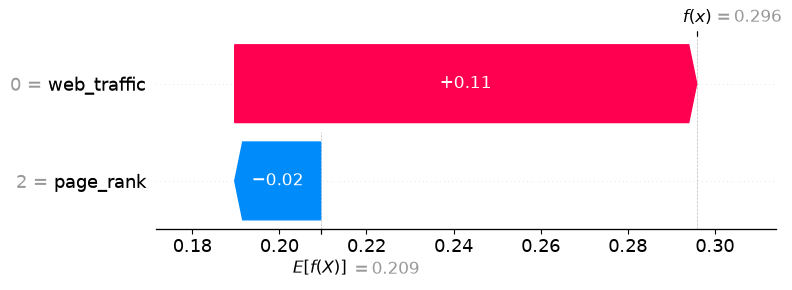

In [61]:
feature_names = [F1, F2]
X_ref = X_train[[F1, F2]].values

# LIME explanation of High risk.
brb_lime = LimeTabularExplainer(X_ref, feature_names=feature_names, discretize_continuous=False, random_state=SEED)
lime_exp = brb_lime.explain_instance(url, brb_predict_proba, labels=(2,), num_features=2, num_samples=2000)

print("LIME (High):", lime_exp.as_list(label=2))
print("Fit score:", round(lime_exp.score, 3))

# SHAP explanation of High risk.
background = shap.sample(X_ref, 100, random_state=SEED)
brb_shap = shap.KernelExplainer(brb_predict_proba, background)
sv_brb = brb_shap(url.reshape(1, -1))
sv_brb.feature_names = feature_names

shap.plots.waterfall(sv_brb[0, :, 2])

### Check yourself
<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Was the BRB fooled too, and which rule is most to blame? </p>

<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">
Yes, the BRB was also fooled by the legitimate URL. R4 had the largest activation weight (0.67), while R1 also contributed (0.33). After changing R4 to higher risk, the High-risk belief increased from 0.296 to 0.639, making the wrong decision even stronger.</p>

<p style="color: #3777b8; font-weight: 500; margin-bottom: 8px;">Do LIME and SHAP agree on which input pushes High risk most? </p>
<p style="color: #27AE60; background-color: #F4FBF7; padding: 10px; border-left: 4px solid #27AE60; border-radius: 4px;">
LIME and SHAP do not agree on which input matters most. SHAP attributes most of the High-risk belief to web_traffic (+0.11, versus -0.02 for page_rank), moving it from the base value 0.209 to 0.296. LIME instead gives page_rank the larger weight (-0.185 versus -0.124 for web_traffic).

